# Jetsound: Sound detection with Jetson Nano

## Data collection and feature extraction

The data that we are working with in this assignment is sounds, specifically sounds coming from hand claps, key chains and keyboard typing. The goal is to train a model that, taking sound from a microphone, can distinguish between these sounds by looking at their mel spectrogram.

The dataset was generated by us applying the following method:
* Finding 5 different keyboards, 5 different keychains and 5 different ways to clap hands (rythm, distance from mic)
* Recording a 90s recording of each one of the items. 450s of data per class.
* Split into snippet of 3s. 150 samples per class
* One out of the five recordings per class is selected for testing. The data is then split in training (80%) and testing (20%).

In [ ]:
#INITIALIZATION
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2
#import librosa
import math
from scipy.ndimage import gaussian_filter

DATADIR = "sound_database"
DATASET_PATH = "dataset"

CATEGORIES = ['Claps', 'Keyboard', 'Keys']

RECORD_SECONDS = 3 #seconds     # X resolution of the spectrograms (basically image width) depends on sampling rate
SRATE = 44100
CHUNK = 1024
N_MELS = 128                    # Y resolution of the spectrograms (basically image height)
HOP_LENGTH = 512
N_FFT = 2048
FMAX = 8000
BLUR_SIGMA = 0.3

The following function takes .wav audio samples and creates a mel spectrogram out of them. This will be the data from which out CNN will be trained on.

In [ ]:
# OG spectrogram maker
import numpy as np
import librosa
import scipy.ndimage

def convert_to_spectrogram(audio_signal, sample_rate, n_mels=N_MELS, n_fft=N_FFT, hop_length=HOP_LENGTH, fmax=FMAX, target_width=259, blur_sigma=BLUR_SIGMA):
    """
    Unified pre-processing function.
    Returns:
        model_input: 4D tensor (1, 128, 259, 1) for the model
        plot_data: 2D array (128, 259) for visualization
    """
    
    # 1. Generate Mel Spectrogram
    # explicit params ensure consistency between Training and Live
    mel_spec = librosa.feature.melspectrogram(
        y=audio_signal, 
        sr=sample_rate, 
        n_mels=n_mels, 
        n_fft=n_fft, 
        hop_length=hop_length,
        fmax=fmax 
    )
    
    # 2. Convert to Decibels
    mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
    
    # 3. Normalize to [0, 1]
    # (Matches your training function logic)
    spec_min = mel_spec_db.min()
    spec_max = mel_spec_db.max()
    
    if spec_max - spec_min > 0:
        mel_spec_norm = (mel_spec_db - spec_min) / (spec_max - spec_min)
    else:
        mel_spec_norm = mel_spec_db # Handle silence/errors
        
    # 4. Shape Enforcement (Pad or Trim to target_width)
    # This was missing in your training func but is CRITICAL for the model input shape
    current_width = mel_spec_norm.shape[1]
    
    if current_width < target_width:
        padding = target_width - current_width
        mel_spec_norm = np.pad(mel_spec_norm, ((0, 0), (0, padding)))
    elif current_width > target_width:
        mel_spec_norm = mel_spec_norm[:, :target_width]
        
    # 5. Optional Blur (Matches your training function)
    if blur_sigma > 0:
        mel_spec_norm = gaussian_filter(mel_spec_norm, sigma=BLUR_SIGMA)
        
    # 6. Prepare Final Output
    # Create 2D version for plotting
    plot_data = mel_spec_norm
    
    # Create 4D version for Model (Batch, Height, Width, Channels)
    # (128, 259) -> (1, 128, 259, 1)
    model_input = mel_spec_norm[np.newaxis, ..., np.newaxis]
    
    return model_input, plot_data

In [2]:
# Functions for librosaless live testing

from scipy.signal import stft

def hz_to_mel(f):
    return 2595.0 * np.log10(1.0 + f / 700.0)

# Convert Mel scale back to frequency in Hz
def mel_to_hz(m):
    return 700.0 * (10.0**(m / 2595.0) - 1.0)

def mel_filterbank(n_mels, n_fft, sample_rate, fmax):
    """
    Create a Mel filterbank matrix to convert FFT bins to Mel bins.
    
    Parameters:
        n_mels: number of Mel bands
        n_fft: FFT size
        sample_rate: sampling rate of audio
        fmax: max frequency to include in Mel scale
    
    Returns:
        filterbank: shape (n_mels, n_fft//2+1)
    """
    # Convert min and max frequencies to Mel scale
    mel_min = hz_to_mel(0)
    mel_max = hz_to_mel(fmax)

    # Equally spaced points in Mel scale
    mel_points = np.linspace(mel_min, mel_max, n_mels + 2)

    # Convert Mel points back to Hz
    hz_points = mel_to_hz(mel_points)

    # Map Hz points to nearest FFT bin indices
    bin_points = np.round((n_fft + 1) * hz_points / sample_rate).astype(int)

    # Initialize filterbank matrix
    filterbank = np.zeros((n_mels, n_fft // 2 + 1))

    # Create triangular filters
    for m in range(1, n_mels + 1):
        f_left = bin_points[m - 1]     # left edge of triangle
        f_center = bin_points[m]       # center (peak) of triangle
        f_right = bin_points[m + 1]    # right edge of triangle

        # Avoid zero-width triangles
        if f_center == f_left:
            f_center += 1
        if f_right == f_center:
            f_right += 1

        # Rising slope
        for k in range(f_left, f_center):
            filterbank[m - 1, k] = (k - f_left) / (f_center - f_left)

        # Falling slope
        for k in range(f_center, f_right):
            filterbank[m - 1, k] = (f_right - k) / (f_right - f_center)

    return filterbank

def librosaless_spectrogram(audio_signal, sample_rate, n_mels=N_MELS, n_fft=N_FFT, hop_length=HOP_LENGTH, fmax=FMAX, target_width=259, blur_sigma=BLUR_SIGMA):
    """
    Unified pre-processing function.
    Returns:
        model_input: 4D tensor (1, 128, 259, 1) for the model
        plot_data: 2D array (128, 259) for visualization
    """
    
    # 1. Generate Mel Spectrogram
    # --- Compute STFT ---
    # Returns frequency bins (f), time bins (t), and complex STFT matrix (Zxx)
    _, _, Zxx = stft(
        audio_signal,
        fs=sample_rate,
        nperseg=n_fft,
        noverlap=n_fft - hop_length,
        window="hann",
        padded=False,
        boundary=None
    )

    # --- Compute power spectrogram ---
    # Take magnitude squared of STFT
    power_spec = np.abs(Zxx) ** 2

    # --- Apply Mel filterbank ---
    mel_fb = mel_filterbank(n_mels, n_fft, sample_rate, fmax)
    # Multiply filterbank with power spectrogram
    mel_spec = np.dot(mel_fb, power_spec)
    
    # --- Convert to decibels (dB) ---
    mel_spec_db = 10.0 * np.log10(mel_spec + 1e-10)  # avoid log(0)
    
    # 3. Normalize to [0, 1]
    # (Matches your training function logic)
    spec_min = mel_spec_db.min()
    spec_max = mel_spec_db.max()
    
    if spec_max - spec_min > 0:
        mel_spec_norm = (mel_spec_db - spec_min) / (spec_max - spec_min)
    else:
        mel_spec_norm = mel_spec_db # Handle silence/errors
        
    # 4. Shape Enforcement (Pad or Trim to target_width)
    # This was missing in your training func but is CRITICAL for the model input shape
    current_width = mel_spec_norm.shape[1]
    
    if current_width < target_width:
        padding = target_width - current_width
        mel_spec_norm = np.pad(mel_spec_norm, ((0, 0), (0, padding)))
    elif current_width > target_width:
        mel_spec_norm = mel_spec_norm[:, :target_width]
        
    # 5. Optional Blur (Matches your training function)
    if blur_sigma > 0:
        mel_spec_norm = gaussian_filter(mel_spec_norm, sigma=BLUR_SIGMA)
        
    # 6. Prepare Final Output
    # Create 2D version for plotting
    plot_data = mel_spec_norm
    
    # Create 4D version for Model (Batch, Height, Width, Channels)
    # (128, 259) -> (1, 128, 259, 1)
    model_input = mel_spec_norm[np.newaxis, ..., np.newaxis]
    
    return model_input, plot_data

The following function splits the recordings and saves a spectrogram for each snippet in the "dataset" folder.

In [9]:
#SPLITTER FUNCTION AND DATASET GENERATION
import os
import math
import numpy as np
import matplotlib.pyplot as plt
import librosa

def split_rec_and_create_dataset():
    # Settings
    overlap_ratio = 0.50  # 50% overlap between the snippets
    
    # 1. Create the main folder if it doesn't exist
    if not os.path.exists(DATASET_PATH):
        os.makedirs(DATASET_PATH)
        print(f"Created folder: {DATASET_PATH}")
    
    count = 0
    
    for category in CATEGORIES:
        path = os.path.join(DATADIR, category)
        
        if not os.path.exists(path):
            print(f"Skipping {category}: Folder not found at {path}")
            continue

        print(f"Processing category: {category}")

        for fname in os.listdir(path):
            if not fname.lower().endswith('.wav'):
                continue
                
            file_path = os.path.join(path, fname)
            base_name = os.path.splitext(fname)[0]
            
            try:
                audio, sr = librosa.load(file_path, sr=None)
                
                total_samples = len(audio)
                samples_per_chunk = int(RECORD_SECONDS * sr)
                
                # If we want 50% overlap, we step forward by 50% of the chunk length
                step_size = int(samples_per_chunk * (1 - overlap_ratio))
                
                current_start = 0
                part_idx = 1
                
                # --- NEW LOOP STRUCTURE ---
                # Keep going as long as the start point is within the audio file
                while current_start < total_samples:
                    
                    # Define the end point for this specific window
                    current_end = current_start + samples_per_chunk
                    
                    chunk_audio = audio[current_start : current_end]
                    
                    # Zero Padding (Logic remains the same)
                    if len(chunk_audio) < samples_per_chunk:
                        padding_needed = samples_per_chunk - len(chunk_audio)
                        chunk_audio = np.pad(chunk_audio, (0, padding_needed), mode='constant')
                    
                    # Convert to spectrogram
                    tensor, image = convert_to_spectrogram(chunk_audio, sr, N_MELS, fmax=FMAX)
                    
                    # Save
                    out_name = f"{base_name}_{part_idx}.png"
                    out_path = os.path.join(DATASET_PATH, out_name)
                    
                    plt.imsave(out_path, image, origin='lower', cmap='gray')
                    
                    count += 1
                    part_idx += 1
                    
                    # --- MOVE THE WINDOW FORWARD ---
                    current_start += step_size
                
            except Exception as e:
                print(f"Error processing {fname}: {e}")
                
    print(f"Done! Saved {count} spectrogram images to '{DATASET_PATH}'")
    
split_rec_and_create_dataset()

Processing category: Claps
Processing category: Keyboard
Processing category: Keys
Done! Saved 900 spectrogram images to 'dataset'


In [ ]:
#SAMPLE VISUALIZER
import matplotlib.pyplot as plt
import os

# The specific files you want to compare
files_to_plot = ["Keys4_50.png", "Keys4_33.png", "Keys4_18.png"]

# Create a grid with 3 rows and 1 column
# figsize=(width, height). (8, 12) makes it tall enough for 3 stacked images.
fig, axes = plt.subplots(3, 1, figsize=(8, 12))

for i, filename in enumerate(files_to_plot):
    file_path = os.path.join("dataset", filename)
    
    # Check if file exists to prevent crashing if one is missing
    if os.path.exists(file_path):
        # Load the image
        image_data = plt.imread(file_path)
        
        # Plot on the specific subplot axis (axes[i])
        axes[i].imshow(image_data, origin='lower', cmap='gray', aspect='auto')
        axes[i].set_title(filename)
        axes[i].set_ylabel("Frequency")
        axes[i].set_xlabel("Time")
    else:
        print(f"Warning: Could not find {file_path}")

# Adjust layout so titles and labels don't overlap
plt.tight_layout()
plt.show()

The following function loads all the saved spectrograms and creates a testset and a trainset.

In [12]:
#TRAIN SET AND TEST SET CREATION (LOSO)
import os
import cv2
import numpy as np
from tensorflow.keras.utils import to_categorical

IMG_HEIGHT = N_MELS  # Must match your saved images
IMG_WIDTH = 259   # Must match your saved images

def load_and_split_dataset():
    # Initialize empty lists
    x_train, y_train = [], []
    x_test, y_test = [], []

    print("Loading images...")

    for img_name in os.listdir(DATASET_PATH):
        # Skip non-image files
        if not img_name.endswith(".png"):
            continue

        # --- PARSING THE FILENAME ---
        # Example filename: "Keys5_19.png"
        
        # 1. Split "Keys5" from "19.png"
        parts = img_name.split('_') 
        prefix = parts[0] # "Keys5"
        
        # 2. Identify the Category and Recording ID
        category = None
        for cat in CATEGORIES:
            if prefix.startswith(cat):
                category = cat
                break
        
        if category is None:
            print(f"Skipping {img_name}: Could not match category")
            continue
            
        # 3. Extract the recording number (Remove "Keys" from "Keys5" -> "5")
        recording_id = prefix.replace(category, "")
        
        # 4. Get the numerical label (0, 1, or 2)
        label = CATEGORIES.index(category)

        # --- LOAD IMAGE ---
        img_path = os.path.join(DATASET_PATH, img_name)
        
        # Read as GRAYSCALE
        # This ignores the Magma colors and loads strictly based on brightness
        img_array = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        
        # Safety resize (ensures stacking doesn't crash if one image is off by 1 pixel)
        img_array = cv2.resize(img_array, (IMG_WIDTH, IMG_HEIGHT))
        
        # Normalize pixel values to be between 0 and 1
        img_array = img_array / 255.0

        # --- SPLIT INTO TRAIN VS TEST ---
        # If the recording ID is '5', it goes to TEST. Everything else goes to TRAIN.
        if recording_id == '5':
            x_test.append(img_array)
            y_test.append(label)
        else:
            x_train.append(img_array)
            y_train.append(label)

    # Convert lists to Numpy Arrays
    x_train = np.array(x_train)
    y_train = np.array(y_train)
    x_test = np.array(x_test)
    y_test = np.array(y_test)
    
    # We need to add a dimension to specify the number of channels (1)
    x_train = x_train[..., np.newaxis]
    x_test = x_test[..., np.newaxis]

    # --- ONE-HOT ENCODING ---
    # Converts label "0" to "[1, 0, 0]"
    y_train = to_categorical(y_train, num_classes=len(CATEGORIES))
    y_test = to_categorical(y_test, num_classes=len(CATEGORIES))

    return x_train, y_train, x_test, y_test

# Run the function
x_train, y_train, x_test, y_test = load_and_split_dataset()

# --- VERIFY THE RESULTS ---
print(f"\n--- Data Loaded ---")
print(f"Training Data Shape (x_train): {x_train.shape}") # Should look like (Num_Samples, Num_Mels, Num_SoundSamples)   (360, 128, 259, 1)
print(f"Training Labels Shape (y_train): {y_train.shape}") #Should look like (Num_Samples, Num_Categories)              (360, 3)
print(f"Test Data Shape (x_test):      {x_test.shape}")
print(f"Test Labels Shape (y_test):      {y_test.shape}")

Loading images...

--- Data Loaded ---
Training Data Shape (x_train): (720, 128, 259, 1)
Training Labels Shape (y_train): (720, 3)
Test Data Shape (x_test):      (180, 128, 259, 1)
Test Labels Shape (y_test):      (180, 3)


Snippet to take a look at the dataset

In [ ]:
#Check 1 image from test or train
Example = 100 #Choose which sample

sample = x_train[Example]           #You can also look into the test set by changing this to x_test
label_data = y_train[Example]       #and y_test
class_index = np.argmax(label_data)
class_name = CATEGORIES[class_index]
plot_data = sample.squeeze()

plt.imshow(plot_data, cmap='gray', origin='lower', aspect='auto')

plt.axis("off")
plt.title(f"Class: {class_name}")
plt.show()

## Network architecture

In [ ]:
# MEga simple model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Dropout, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.regularizers import l2

# Define L2 regularization strength
reg = l2(0.001)

model = Sequential([
    # --- Block 1: Simple Feature Extraction ---
    # Only 8 filters. We keep it very simple.
    Conv2D(8, (3,3), activation='relu', padding='same', kernel_regularizer=reg, input_shape=(N_MELS, IMG_WIDTH, 1)),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    
    # --- Block 2: Shape Detection ---
    Conv2D(16, (3,3), activation='relu', padding='same', kernel_regularizer=reg),
    BatchNormalization(),
    MaxPooling2D((2,2)),

    # --- Block 3: Texture Detection ---
    Conv2D(32, (3,3), activation='relu', padding='same', kernel_regularizer=reg),
    BatchNormalization(),
    MaxPooling2D((2,2)),

    # --- THE MAGIC TRICK: Global Average Pooling ---
    # Replaces Flatten(). Instead of a vector of 10,000 numbers, 
    # it condenses the image into just 32 numbers (one per filter).
    # This makes it almost impossible to overfit.
    GlobalAveragePooling2D(),
    
    # --- Classifier ---
    Dropout(0.5), # Block 50% of neurons to force redundancy
    Dense(3, activation='softmax') 
])

from tensorflow.keras.optimizers import Adam
# Low learning rate for stability
model.compile(optimizer=Adam(learning_rate=0.0005),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

In [ ]:
# Model definition (simplified & regularized)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam

input_shape = x_train.shape[1:]  # (n_mels, time_steps, 1)

model = Sequential([
    # Conv Block 1
    Conv2D(16, (7,3), activation='relu', padding='same', input_shape=input_shape),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.3),
    
    # Conv Block 2
    Conv2D(16, (7,3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.3),
    
    # Conv Block 3
    Conv2D(16, (3,3), activation='relu', padding='same'),
    BatchNormalization(),
    GlobalAveragePooling2D(),  # reduces parameters and prevents overfitting
    
    # Dense + Output
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.4),
    
    Dense(len(CATEGORIES), activation='softmax')
])

# Use a smaller learning rate to stabilise training
model.compile(
    optimizer=Adam(learning_rate=1e-1),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

## Model training

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

# 1. STOPPING: Stop if validation loss doesn't improve for 10 epochs (patience)
early_stop = EarlyStopping(
    monitor='val_loss', 
    patience=5, 
    restore_best_weights=True, # reverts to the best epoch automatically
    verbose=1
)

# 2. SAVING: Save the best model to a file
# Define Checkpoint for the modern .keras format
checkpoint_keras = ModelCheckpoint(
    'best_audio_model.keras', 
    monitor='val_loss', 
    save_best_only=True, 
    verbose=1
)

# Define Checkpoint for the legacy .h5 format
checkpoint_h5 = ModelCheckpoint(
    'best_audio_model.h5', 
    monitor='val_loss', 
    save_best_only=True, 
    verbose=0 # Set to 0 to avoid double printing lines in the console
)

# 3. FITTING
history = model.fit(
    x_train, y_train,
    epochs=100,
    batch_size=32,         # 32 is standard. For small data, 16 is also okay.
    validation_data=(x_test, y_test),
    # Add both variables to this list
    callbacks=[checkpoint_keras, checkpoint_h5]
)

import matplotlib.pyplot as plt

# 1. Plot the "Loss"
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1) # Left graph
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss (Lower is Better)')
plt.xlabel('Epochs')
plt.ylabel('Error')
plt.legend()

# 2. Plot the "Accuracy"
plt.subplot(1, 2, 2) # Right graph
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy (Higher is Better)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

from sklearn.metrics import confusion_matrix
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Get the model's predictions (these will be probabilities)
predictions = model.predict(x_test)

# 2. Convert One-Hot Encoded labels back to Single Integers
# Example: [0, 1, 0] -> 1 (Keyboard)
y_pred_classes = np.argmax(predictions, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# 4. (Optional) Plot a nice heatmap for the Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true_classes, y_pred_classes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=CATEGORIES, yticklabels=CATEGORIES)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Live data Collection & Actuators 



In [ ]:
import pyaudio
import numpy as np
import librosa
import tensorflow as tf
import time
from IPython.display import clear_output

# --- Configuration ---
FORMAT = pyaudio.paInt16
CHANNELS = 1

MODEL_PATH = "Best Models Folder/Yvette_1.keras"
#MODEL_PATH = "best_audio_ model.keras"

# --- Load Model ---
try:
    print("Loading model...")
    model = tf.keras.models.load_model(MODEL_PATH)
    print(f"Model loaded: {model}")
except Exception as e:
    print(f"Error loading model: {e}")
    exit()

# --- Audio Setup ---
audio = pyaudio.PyAudio()
stream = audio.open(format=FORMAT, channels=CHANNELS,
                    rate=SRATE, input=True,
                    frames_per_buffer=CHUNK)

chunks_per_cycle = int(SRATE / CHUNK * RECORD_SECONDS)

print("\n--- Starting Continuous Prediction Loop---")

try:
    while True:
        # 1. Capture Audio
        frames = []
        for i in range(0, chunks_per_cycle):
            try:
                data = stream.read(CHUNK, exception_on_overflow=False)
                frames.append(data)
            except IOError:
                continue
        
        if len(frames) < chunks_per_cycle:
            continue # Skip incomplete reads

        # 2. Process to Float
        audio_data = np.frombuffer(b''.join(frames), dtype=np.int16)
        audio_float = audio_data.astype(np.float32) / 32768.0
        
        # We get the prediction tensor AND the plot data in one go
        input_tensor, plot_data = convert_to_spectrogram(
            audio_signal=audio_float,
            sample_rate=SRATE,
            n_mels=N_MELS,
            n_fft=N_FFT,
            hop_length=HOP_LENGTH,
            fmax=FMAX,
            target_width=259,
            blur_sigma=BLUR_SIGMA
        )
        
        # Training images (origin='lower') are read by Keras top-down (High->Low).
        # Live data is generated Low->High. We must flip it to match the model's training.
        
        # Flip the input tensor (Batch, Freq, Time, Channels) along axis 1 (Freq)
        input_tensor = np.flip(input_tensor, axis=1)
        
        # Flip the plot data so the visual matches what the model sees
        plot_data = np.flipud(plot_data)
        
        # 4. Predict
        prediction = model.predict(input_tensor, verbose=0)
        predicted_index = np.argmax(prediction)
        confidence = np.max(prediction)
        
        if predicted_index < len(CATEGORIES):
            class_name = CATEGORIES[predicted_index]
        else:
            class_name = "Unknown"
            
        # 5. Visualization
        clear_output(wait=True)
        print(f"Prediction: {class_name} ({confidence:.2%} confidence)")

        plt.figure(figsize=(10, 4))
        plt.imshow(plot_data, 
                   origin='upper', # Matches Keras top-down reading
                   aspect='auto', 
                   cmap='gray')
        
        plt.colorbar(format='%+2.2f')
        plt.title(f"Model Input (Flipped): {class_name} ({confidence:.0%})")
        plt.tight_layout()
        plt.show()
        plt.close()

except KeyboardInterrupt:
    print("\nStopping...")
finally:
    stream.stop_stream()
    stream.close()
    audio.terminate()

Prediction: Claps (99.98% confidence)


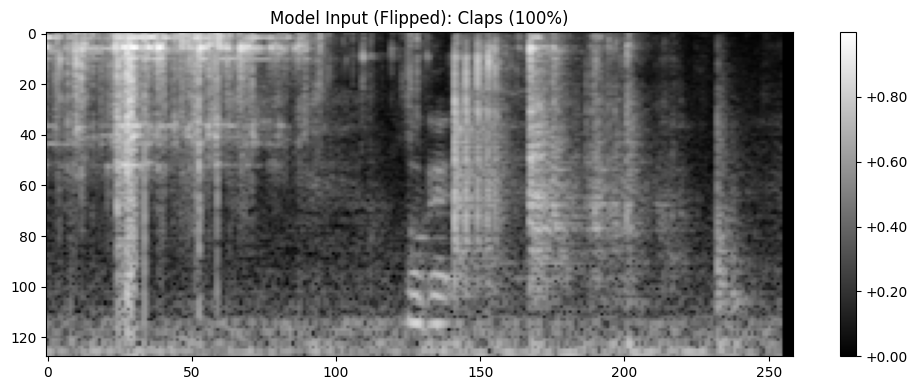


Stopping...


In [ ]:
# Same as above but librosaless
import pyaudio
import numpy as np
import tensorflow as tf
import time
from IPython.display import clear_output

# --- Configuration ---
FORMAT = pyaudio.paInt16
CHANNELS = 1
T_SAMP = 259


MODEL_PATH = "Best Models Folder/Yvette_1.keras"
#MODEL_PATH = "best_audio_ model.keras"

# --- Load Model ---
try:
    print("Loading model...")
    model = tf.keras.models.load_model(MODEL_PATH)
    print(f"Model loaded: {model}")
except Exception as e:
    print(f"Error loading model: {e}")
    exit()

# --- Audio Setup ---
audio = pyaudio.PyAudio()
stream = audio.open(format=FORMAT, channels=CHANNELS,
                    rate=SRATE, input=True,
                    frames_per_buffer=CHUNK)

chunks_per_cycle = int(SRATE / CHUNK * RECORD_SECONDS)

print("\n--- Starting Continuous Prediction Loop---")

try:
    while True:
        # 1. Capture Audio
        frames = []
        for i in range(0, chunks_per_cycle):
            try:
                data = stream.read(CHUNK, exception_on_overflow=False)
                frames.append(data)
            except IOError:
                continue
        
        if len(frames) < chunks_per_cycle:
            continue # Skip incomplete reads

        # 2. Process to Float
        audio_data = np.frombuffer(b''.join(frames), dtype=np.int16)
        audio_float = audio_data.astype(np.float32) / 32768.0
        
        # --- 2. Generate Mel spectrogram ---
        input_tensor, plot_data = librosaless_spectrogram(
            audio_signal=audio_float,
            sample_rate=SRATE,
            n_mels=N_MELS,
            fmax=8000,
            n_fft=N_FFT,
            hop_length=HOP_LENGTH
        )
            
        # Training images (origin='lower') are read by Keras top-down (High->Low).
        # Live data is generated Low->High. We must flip it to match the model's training.
        
        # Flip the input tensor (Batch, Freq, Time, Channels) along axis 1 (Freq)
        input_tensor = np.flip(input_tensor, axis=1)
        
        # Flip the plot data so the visual matches what the model sees
        plot_data = np.flipud(plot_data)
        
        # 4. Predict
        prediction = model.predict(input_tensor, verbose=0)
        predicted_index = np.argmax(prediction)
        confidence = np.max(prediction)
        
        if predicted_index < len(CATEGORIES):
            class_name = CATEGORIES[predicted_index]
        else:
            class_name = "Unknown"
            
        # 5. Visualization
        clear_output(wait=True)
        print(f"Prediction: {class_name} ({confidence:.2%} confidence)")

        plt.figure(figsize=(10, 4))
        plt.imshow(plot_data, 
                   origin='upper', # Matches Keras top-down reading
                   aspect='auto', 
                   cmap='gray')
        
        plt.colorbar(format='%+2.2f')
        plt.title(f"Model Input (Flipped): {class_name} ({confidence:.0%})")
        plt.tight_layout()
        plt.show()
        plt.close()

except KeyboardInterrupt:
    print("\nStopping...")
finally:
    stream.stop_stream()
    stream.close()
    audio.terminate()

In [ ]:
import tensorflow as tf

# 1. Load Yvette's full model
model = tf.keras.models.load_model("Best Models Folder/Yvette_1.keras")

# 2. Print the summary so you can verify the shape later
model.summary()

# 3. Save ONLY the weights to the universal .h5 format
model.save_weights("yvette_weights.weights.h5")

print("Weights saved. Transfer 'yvette_custom_weights.h5' to the Jetson.")

This code rebuilds a new model with the weights that Yvette had on the keras model.

In [ ]:
# Deploy the model on the Jetson
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, Input

# 1. DEFINE THE ARCHITECTURE
# ⚠️ CRITICAL: This must match the original training code EXACTLY.
# If you used the "Improved Model" from our earlier chat, it looks like this:
def build_custom_model():
    model = Sequential([
        # Block 1
        Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(128, 259, 1)),
        BatchNormalization(),
        MaxPooling2D((2,2)),
        
        # Block 2
        Conv2D(64, (3,3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2,2)),

        # Block 3
        Conv2D(128, (3,3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2,2)),
    
        # Classifier
        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(3, activation='softmax')
    ])
    return model

# 2. CREATE THE EMPTY SHELL
model = build_custom_model()

# 3. LOAD THE WEIGHTS
# The numbers from the PC will fill the empty layers here.
try:
    model.load_weights("yvette_custom_weights.h5")
    print("✅ Custom model weights loaded successfully!")
except ValueError as e:
    print("❌ Shape Mismatch! Did you change the number of filters or layers?")
    print("The architecture in this script must match Yvette's training script exactly.")
    print(e)

# 4. COMPILE (Required to run predictions)
# Use the same optimizer/loss as before
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Now you are ready to predict
# prediction = model.predict(input_data)

## Validation

You need the library "pyaudio" to test this feature.

    pip install pyaudio
    
    conda install conda-forge::pyaudio

In [ ]:
# import pyaudio
# import wave

# # Configuration parameters
# FORMAT = pyaudio.paInt16  # 16-bit resolution
# CHANNELS = 1              # Mono recording
# RATE = 44100              # Sample rate (44.1kHz is standard)
# CHUNK = 1024              # Buffer size
# RECORD_SECONDS = 5        # Duration of recording
# OUTPUT_FILENAME = "test_recording.wav"

# audio = pyaudio.PyAudio()

# # Start Recording
# stream = audio.open(format=FORMAT, channels=CHANNELS,
#                     rate=RATE, input=True,
#                     frames_per_buffer=CHUNK)

# print("Recording...")

# frames = []

# for i in range(0, int(RATE / CHUNK * RECORD_SECONDS)):
#     data = stream.read(CHUNK)
#     frames.append(data)

# print("Finished recording.")

# # Stop and close the stream
# stream.stop_stream()
# stream.close()
# audio.terminate()

# # Save the recorded data as a WAV file 
# # (THIS NEEDS TO BE CHANGED SO IT IS STORED IN MEMORY TO BE USED IN REAL TIME)
# with wave.open(OUTPUT_FILENAME, 'wb') as wf:
#     wf.setnchannels(CHANNELS)
#     wf.setsampwidth(audio.get_sample_size(FORMAT))
#     wf.setframerate(RATE)
#     wf.writeframes(b''.join(frames))

# print(f"File saved as {OUTPUT_FILENAME}")